# AI Prediction Scores

Compare the AI prediction scores in ClinVar variants and 1% variants.

In [5]:
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# import pickle

## Loading data

### VarChAMP variants (~8k)

In [6]:
varchamp_al_df = pl.scan_csv("../../1_allele_collection/3_outputs/varchamp_consolidated_alleles_clinvar_gnomad.tsv", 
                            infer_schema_length=10000, 
                            separator="\t")
varchamp_al_df.collect()

orf_id,symbol,nt_change,aa_change,ensembl_gene_id,chr,chr_pos_38,spdi,ccsb_allele_id,ccsb_mutation_id,mutation_id_rc4,mutation_id_cegs2,mutation_id_edgotyping3,entry_plate,entry_well,collection,sequence,#AlleleID,Type,Name,GeneID,GeneSymbol,HGNC_ID,ClinicalSignificance,ClinSigSimple,LastEvaluated,RS# (dbSNP),nsv/esv (dbVar),RCVaccession,PhenotypeIDS,PhenotypeList,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,Stop,Cytogenetic,ReviewStatus,NumberSubmitters,Guidelines,TestedInGTR,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,chrom,ref,alt,varid,gnomad_af
i64,str,str,str,str,str,i64,str,str,str,str,str,str,str,str,str,str,f64,str,str,f64,str,str,str,f64,str,f64,str,str,str,str,str,str,str,str,str,f64,f64,str,str,f64,str,str,str,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,str,str,str,str,f64
2,"""GBA""","""160G>C""","""Val54Leu""","""ENSG00000177628""","""1""",155240033,"""NC_000001.11:155240033:C:G""","""ALE0000584""","""CCSBVarC000001""","""6""","""NULL""","""NULL""","""GDEhDisVCh_40054""","""F12""","""RC4""","""ATGGAGTTTTCAAGTCCTTCCAGAGAGGAA…",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""chr1""","""G""","""C""","""1-155240033-G-C""",null
2,"""GBA""","""670C>T""","""Leu224Phe""","""ENSG00000177628""","""1""",155238225,"""NC_000001.11:155238225:G:A""","""ALE00000002""","""CCSBVarC000002""","""73""","""NULL""","""NULL""","""GDEhDisVCh_40054""","""C12""","""RC4""","""ATGGAGTTTTCAAGTCCTTCCAGAGAGGAA…",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""chr1""","""C""","""T""","""1-155238225-C-T""",null
2,"""GBA""","""887G>A""","""Arg296Gln""","""ENSG00000177628""","""1""",155237453,"""NC_000001.11:155237453:C:T""","""ALE00000003""","""CCSBVarC000003""","""113""","""NULL""","""NULL""","""GDEhDisVCh_40054""","""D12""","""RC4""","""ATGGAGTTTTCAAGTCCTTCCAGAGAGGAA…",19367.0,"""single nucleotide variant""","""NM_000157.4(GBA1):c.887G>A (p.…",2629.0,"""GBA1""","""HGNC:4177""","""Pathogenic""",1.0,"""Feb 09, 2024""",7.8973108e7,"""-""","""RCV000004573|RCV000079357|RCV0…","""MONDO:MONDO:0011945,MedGen:C18…","""Gaucher disease perinatal leth…","""germline;unknown""","""germline""","""GRCh38""","""NC_000001.11""","""1""",1.55237453e8,1.55237453e8,"""1q22""","""criteria provided, multiple su…",15.0,"""-""","""N""","""ClinGen:CA221417,UniProtKB:P04…",3.0,4328.0,1.55237453e8,"""C""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000232587|SCV000321701|SCV0…","""-""","""-""","""887G>A ""","""Arg296Gln""","""NM_000157.4""",2.0,"""1_Pathogenic""","""chr1""","""G""","""A""","""1-155237453-G-A""",null
2,"""GBA""","""1448T>C""","""Leu483Pro""","""ENSG00000177628""","""1""",155235252,"""NC_000001.11:155235252:A:G""","""ALE00000004""","""CCSBVarC000004""","""231""","""NULL""","""NULL""","""GDEhDisVCh_40054""","""E12""","""RC4""","""ATGGAGTTTTCAAGTCCTTCCAGAGAGGAA…",19327.0,"""single nucleotide variant""","""NM_000157.4(GBA1):c.1448T>C (p…",2629.0,"""GBA1""","""HGNC:4177""","""Pathogenic; risk factor""",1.0,"""Nov 27, 2024""",421016.0,"""-""","""RCV000004509|RCV000004511|RCV0…","""MONDO:MONDO:0009266,MedGen:C02…","""Gaucher disease type II|Gauche…","""biparental;de novo;germline;in…","""germline""","""GRCh38""","""NC_000001.11""","""1""",1.55235

### dbNSFP variants (~1.6M)

In [20]:
df_clinvar = pl.scan_parquet("../3_outputs/processed_data/dbnsfp/dbNSFP5.0a_variant.clin_var_re-annot.parquet")

## Optional: explode the variants
# For testing purposes, limit to a small subset:
df_clin_subset_col = df_clinvar.limit(10)
# Collect the subset into an eager DataFrame for inspection
df_clin_subset_col = df_clin_subset_col.collect()
# Automatically detect columns with semicolon-separated patterns.
# We only check columns of Utf8 (string) type.
pattern_cols = [
    col for col in df_clinvar.collect_schema() 
    if df_clin_subset_col[col].dtype == pl.Utf8 and df_clin_subset_col[col].str.contains(";").any()
]
print("Columns containing ';':", pattern_cols)

# Now, suppose you have a function that takes a DataFrame and splits/explodes these columns.
# You can test it on the subset first:
def split_and_explode(df: pl.DataFrame, columns: list) -> pl.DataFrame:
    # Convert each target column from a string to a list (using ";" as separator)
    df = df.with_columns([pl.col(col).str.split(";").alias(col) for col in columns])
    # Explode all the target columns simultaneously.
    return df.explode(columns)

df_clinvar_exploded = df_clinvar.with_columns(
    [pl.col(col).str.split(";").alias(col) for col in pattern_cols]
).explode(pattern_cols)

Columns containing ';': ['aapos', 'genename', 'Ensembl_geneid', 'Ensembl_transcriptid', 'Ensembl_proteinid', 'Uniprot_acc', 'Uniprot_entry', 'HGVSc_snpEff', 'HGVSp_snpEff', 'HGVSc_VEP', 'HGVSp_VEP', 'APPRIS', 'GENCODE_basic', 'TSL', 'VEP_canonical', 'MANE', 'cds_strand', 'refcodon', 'codonpos', 'codon_degeneracy', 'SIFT_score', 'SIFT_pred', 'SIFT4G_score', 'SIFT4G_pred', 'Polyphen2_HDIV_score', 'Polyphen2_HDIV_pred', 'Polyphen2_HVAR_score', 'Polyphen2_HVAR_pred', 'MutationTaster_score', 'MutationTaster_pred', 'MutationTaster_model', 'MutationTaster_trees_benign', 'MutationTaster_trees_deleterious', 'MutationAssessor_score', 'MutationAssessor_pred', 'PROVEAN_score', 'PROVEAN_pred', 'VEST4_score', 'MetaRNN_score', 'MetaRNN_pred', 'REVEL_score', 'MutPred_score', 'MutPred_protID', 'MutPred_AAchange', 'MutPred_Top5features', 'MVP_score', 'gMVP_score', 'MPC_score', 'DEOGEN2_score', 'DEOGEN2_pred', 'LIST-S2_score', 'LIST-S2_pred', 'VARITY_R_score', 'VARITY_ER_score', 'VARITY_R_LOO_score', 'VA

### Merge them together

In [24]:
varchamp_al_df_ai_scores = varchamp_al_df.join(
    df_clinvar_exploded, how="left", 
    left_on="spdi", right_on="SPDI",
    suffix="_dbnsfp"
)
varchamp_al_df_ai_scores = varchamp_al_df_ai_scores.collect()

In [26]:
varchamp_al_df_ai_scores

orf_id,symbol,nt_change,aa_change,ensembl_gene_id,chr,chr_pos_38,spdi,ccsb_allele_id,ccsb_mutation_id,mutation_id_rc4,mutation_id_cegs2,mutation_id_edgotyping3,entry_plate,entry_well,collection,sequence,#AlleleID,Type,Name,GeneID,GeneSymbol,HGNC_ID,ClinicalSignificance,ClinSigSimple,LastEvaluated,RS# (dbSNP),nsv/esv (dbVar),RCVaccession,PhenotypeIDS,PhenotypeList,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,…,RS# (dbSNP)_dbnsfp,nsv/esv (dbVar)_dbnsfp,RCVaccession_dbnsfp,PhenotypeIDS_dbnsfp,PhenotypeList_dbnsfp,Origin_dbnsfp,OriginSimple_dbnsfp,Assembly_dbnsfp,ChromosomeAccession_dbnsfp,Chromosome_dbnsfp,Start_dbnsfp,Stop_dbnsfp,Cytogenetic_dbnsfp,ReviewStatus_dbnsfp,NumberSubmitters_dbnsfp,Guidelines_dbnsfp,TestedInGTR_dbnsfp,OtherIDs_dbnsfp,SubmitterCategories_dbnsfp,VariationID_dbnsfp,PositionVCF_dbnsfp,ReferenceAlleleVCF_dbnsfp,AlternateAlleleVCF_dbnsfp,SomaticClinicalImpact_dbnsfp,SomaticClinicalImpactLastEvaluated_dbnsfp,ReviewStatusClinicalImpact_dbnsfp,Oncogenicity_dbnsfp,OncogenicityLastEvaluated_dbnsfp,ReviewStatusOncogenicity_dbnsfp,SCVsForAggregateGermlineClassification_dbnsfp,SCVsForAggregateSomaticClinicalImpact_dbnsfp,SCVsForAggregateOncogenicityClassification_dbnsfp,clinvar_nt_change_dbnsfp,clinvar_aa_change_dbnsfp,RefSeq_mRNA_dbnsfp,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp
i64,str,str,str,str,str,i64,str,str,str,str,str,str,str,str,str,str,f64,str,str,f64,str,str,str,f64,str,f64,str,str,str,str,str,str,str,str,str,f64,…,i64,str,str,str,str,str,str,cat,str,str,i64,i64,str,cat,i64,str,str,str,i64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i32,cat
2,"""GBA""","""160G>C""","""Val54Leu""","""ENSG00000177628""","""1""",155240033,"""NC_000001.11:155240033:C:G""","""ALE0000584""","""CCSBVarC000001""","""6""","""NULL""","""NULL""","""GDEhDisVCh_40054""","""F12""","""RC4""","""ATGGAGTTTTCAAGTCCTTCCAGAGAGGAA…",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2,"""GBA""","""670C>T""","""Leu224Phe""","""ENSG00000177628""","""1""",155238225,"""NC_000001.11:155238225:G:A""","""ALE00000002""","""CCSBVarC000002""","""73""","""NULL""","""NULL""","""GDEhDisVCh_40054""","""C12""","""RC4""","""ATGGAGTTTTCAAGTCCTTCCAGAGAGGAA…",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2,"""GBA""","""887G>A""","""Arg296Gln""","""ENSG00000177628""","""1""",155237453,"""NC_000001.11:155237453:C:T""","""ALE00000003""","""CCSBVarC000003""","""113""","""NULL""","""NULL""","""GDEhDisVCh_40054""","""D12""","""RC4""","""ATGGAGTTTTCAAGTCCTTCCAGAGAGGAA…",19367.0,"""single nucleotide variant""","""NM_000157.4(GBA1):c.887G>A (p.…",2629.0,"""GBA1""","""HGNC:4177""","""Pathogenic""",1.0,"""Feb 09, 2024""",7.8973108e7,"""-""","""RCV000004573|RCV000079357|RCV0…","""MONDO:MONDO:0011945,MedGen:C18…","""Gaucher disease perinatal leth…","""germline;unknown""","""germline""","""GRCh38""","""NC_000001.11""","""1""",1.55237453e8,…,78973108,"""-""","""RCV000004573|RCV000079357|RCV0…","""MONDO:MONDO:0011945,MedGen:C18…","""Gaucher disease perinatal leth…","""germline;unknown""","""germline""","""GRCh38""","""NC_000001.11""","""1""",155237453,155237453,"""1q22""","""criteria provided, multiple su…",15,"""-""","""N""","""ClinGen:CA221417,UniProtKB:P04…",3,4328,155237453,"""C""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000232587|SCV000321701|SCV0…","""-""","""-""","""887G>A ""","""Arg296Gln""","""NM_000157.4""",2,"""1_Pathogenic"""
2,"""GBA""","""887G>A""","""Arg296Gln""","""ENSG00000177628""","""1""",155237453,"""NC_000001.11:155237453:

In [27]:
varchamp_al_df_ai_dedup = varchamp_al_df_ai_scores.unique(subset=["symbol","aa_change"], keep="first")
varchamp_al_df_ai_dedup.head()

orf_id,symbol,nt_change,aa_change,ensembl_gene_id,chr,chr_pos_38,spdi,ccsb_allele_id,ccsb_mutation_id,mutation_id_rc4,mutation_id_cegs2,mutation_id_edgotyping3,entry_plate,entry_well,collection,sequence,#AlleleID,Type,Name,GeneID,GeneSymbol,HGNC_ID,ClinicalSignificance,ClinSigSimple,LastEvaluated,RS# (dbSNP),nsv/esv (dbVar),RCVaccession,PhenotypeIDS,PhenotypeList,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,…,RS# (dbSNP)_dbnsfp,nsv/esv (dbVar)_dbnsfp,RCVaccession_dbnsfp,PhenotypeIDS_dbnsfp,PhenotypeList_dbnsfp,Origin_dbnsfp,OriginSimple_dbnsfp,Assembly_dbnsfp,ChromosomeAccession_dbnsfp,Chromosome_dbnsfp,Start_dbnsfp,Stop_dbnsfp,Cytogenetic_dbnsfp,ReviewStatus_dbnsfp,NumberSubmitters_dbnsfp,Guidelines_dbnsfp,TestedInGTR_dbnsfp,OtherIDs_dbnsfp,SubmitterCategories_dbnsfp,VariationID_dbnsfp,PositionVCF_dbnsfp,ReferenceAlleleVCF_dbnsfp,AlternateAlleleVCF_dbnsfp,SomaticClinicalImpact_dbnsfp,SomaticClinicalImpactLastEvaluated_dbnsfp,ReviewStatusClinicalImpact_dbnsfp,Oncogenicity_dbnsfp,OncogenicityLastEvaluated_dbnsfp,ReviewStatusOncogenicity_dbnsfp,SCVsForAggregateGermlineClassification_dbnsfp,SCVsForAggregateSomaticClinicalImpact_dbnsfp,SCVsForAggregateOncogenicityClassification_dbnsfp,clinvar_nt_change_dbnsfp,clinvar_aa_change_dbnsfp,RefSeq_mRNA_dbnsfp,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp
i64,str,str,str,str,str,i64,str,str,str,str,str,str,str,str,str,str,f64,str,str,f64,str,str,str,f64,str,f64,str,str,str,str,str,str,str,str,str,f64,…,i64,str,str,str,str,str,str,cat,str,str,i64,i64,str,cat,i64,str,str,str,i64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i32,cat
14117,"""DNM2""","""1684A>G""","""Lys562Glu""","""ENSG00000079805""","""19""",10819992,"""NC_000019.10:10819992:A:G""","""ALE00003072""","""CCSBVarC003072""","""NULL""","""204162""","""2460""","""GDEhDisVCh_40020""","""D01""","""CEGS2""","""ATGGGCAACCGCGGGATGGAAGAGCTGATC…",22316.0,"""single nucleotide variant""","""NM_001005361.3(DNM2):c.1684A>G…",1785.0,"""DNM2""","""HGNC:2974""","""Conflicting classifications of…",1.0,"""Jan 06, 2016""",1.21909088e8,"""-""","""RCV000007700|RCV000789618|RCV0…","""MedGen:C1847903|MONDO:MONDO:00…","""Charcot-Marie-Tooth disease, d…","""germline""","""germline""","""GRCh38""","""NC_000019.10""","""19""",1.0819992e7,…,121909088,"""-""","""RCV000007700|RCV000789618|RCV0…","""MedGen:C1847903|MONDO:MONDO:00…","""Charcot-Marie-Tooth disease, d…","""germline""","""germline""","""GRCh38""","""NC_000019.10""","""19""",10819992,10819992,"""19p13.2""","""no assertion criteria provided""",3,"""-""","""N""","""ClinGen:CA118652,UniProtKB:P50…",3,7277,10819992,"""A""","""G""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000027901|SCV000928984|SCV0…","""-""","""-""","""1684A>G ""","""Lys562Glu""","""NM_001005361.3""",null,"""3_Conflicting"""
53653,"""SLC2A10""","""1276G>T""","""Gly426Trp""","""ENSG00000197496""","""20""",46726312,"""NC_000020.11:46726312:G:T""","""ALE00003857""","""CCSBVarC003857""","""NULL""","""204736""","""NULL""","""GDEhDisVCh_40087""","""D02""","""CEGS2""","""ATGGGCCACTCCCCACCTGTCCTGCCTTTG…",19628.0,"""single nucleotide variant""","""NM_030777.4(SLC2A10):c.1276G>T…",81031.0,"""SLC2A10""","""HGNC:13444""","""Pathogenic/Likely pathogenic""",1.0,"""Aug 08, 2024""",1.21908172e8,"""-""","""RCV000199687|RCV000004851|RCV0…","""MedGen:C3661900|MONDO:MONDO:00…","""not provided|Arterial tortuosi…","""germline""","""germline""","""GRCh38""","""NC_000020.11""","""20""",4.6726312e7,…,121908172,"""-""","""RCV000199687|RCV000004851|RCV0…","""MedGen:C3661900|MONDO:MONDO:00…","""not provided|Arterial tortuosi…","""germline""","""germline""","""GRCh38""","""NC_000020.11""","""20""",46726312,46726312,"""20q13.12""","""criteria provided, multiple su…",8,"""-""","""N""","""ClinGen:CA324232,UniProtKB:O95…",3,4589,46726312,"""G""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000250723|SCV001386351|SCV0…","""-""","""-""","""1276G>T ""","""Gly426Trp""","""NM_030777.4""",2,"""1_Pathogen

In [16]:
symbol_counts = varchamp_al_df_ai_dedup.group_by("symbol").len().sort(by="len", descending=True)
print(symbol_counts.head())

shape: (5, 2)
┌────────┬─────┐
│ symbol ┆ len │
│ ---    ┆ --- │
│ str    ┆ u32 │
╞════════╪═════╡
│ GALT   ┆ 192 │
│ SMAD4  ┆ 128 │
│ DES    ┆ 121 │
│ AGXT   ┆ 98  │
│ CBS    ┆ 83  │
└────────┴─────┘


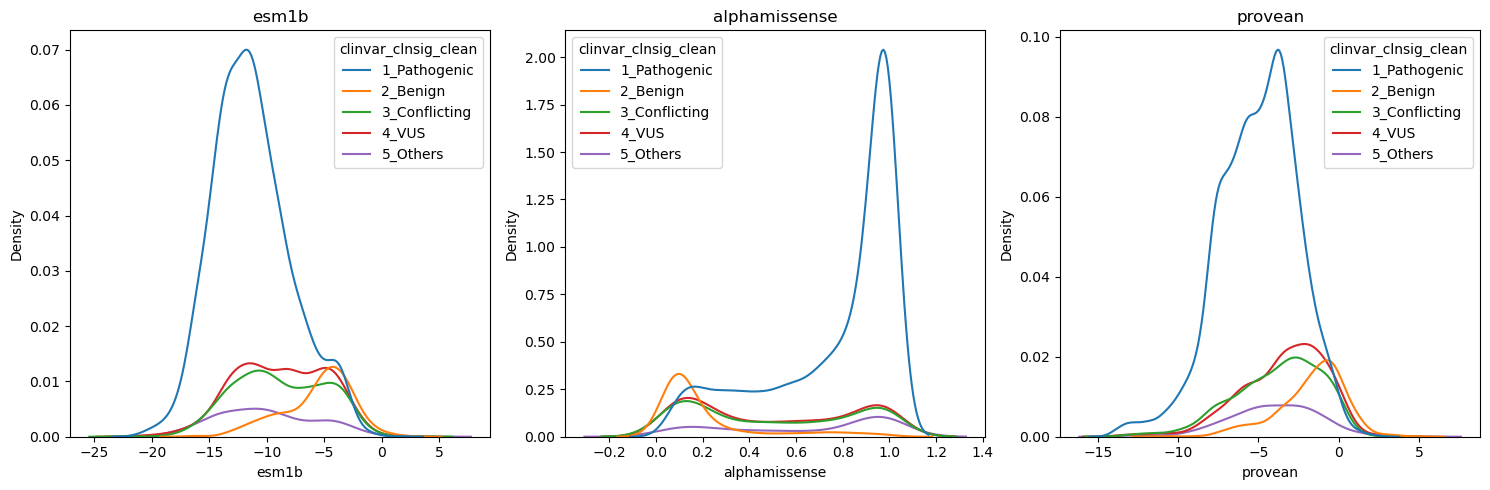

In [60]:
varchamp_al_df_ai_plots = varchamp_al_df_ai_dedup.select(
    pl.col("ESM1b_score","AlphaMissense_score","PROVEAN_score","clinvar_clnsig_clean")
).with_columns(
    pl.col("ESM1b_score").replace(".", None).cast(pl.Float64).alias("esm1b"),
    pl.col("AlphaMissense_score").replace(".", None).cast(pl.Float64).alias("alphamissense"),
    pl.col("PROVEAN_score").replace(".", None).cast(pl.Float64).alias("provean")
)

# Define variables to plot
variables = ["esm1b", "alphamissense", "provean"]

# Create a FacetGrid for multiple subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5)) ## , sharey=True
hue_order = sorted(varchamp_al_df_ai_dedup["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
# Loop through variables and create subplots
for ax, var in zip(axes, variables):
    sns.kdeplot(
        data=varchamp_al_df_ai_plots,
        x=var,
        hue="clinvar_clnsig_clean",
        hue_order=hue_order,
        # kde=True,
        ax=ax
    )
    ax.set_title(var)
plt.tight_layout()
plt.show()

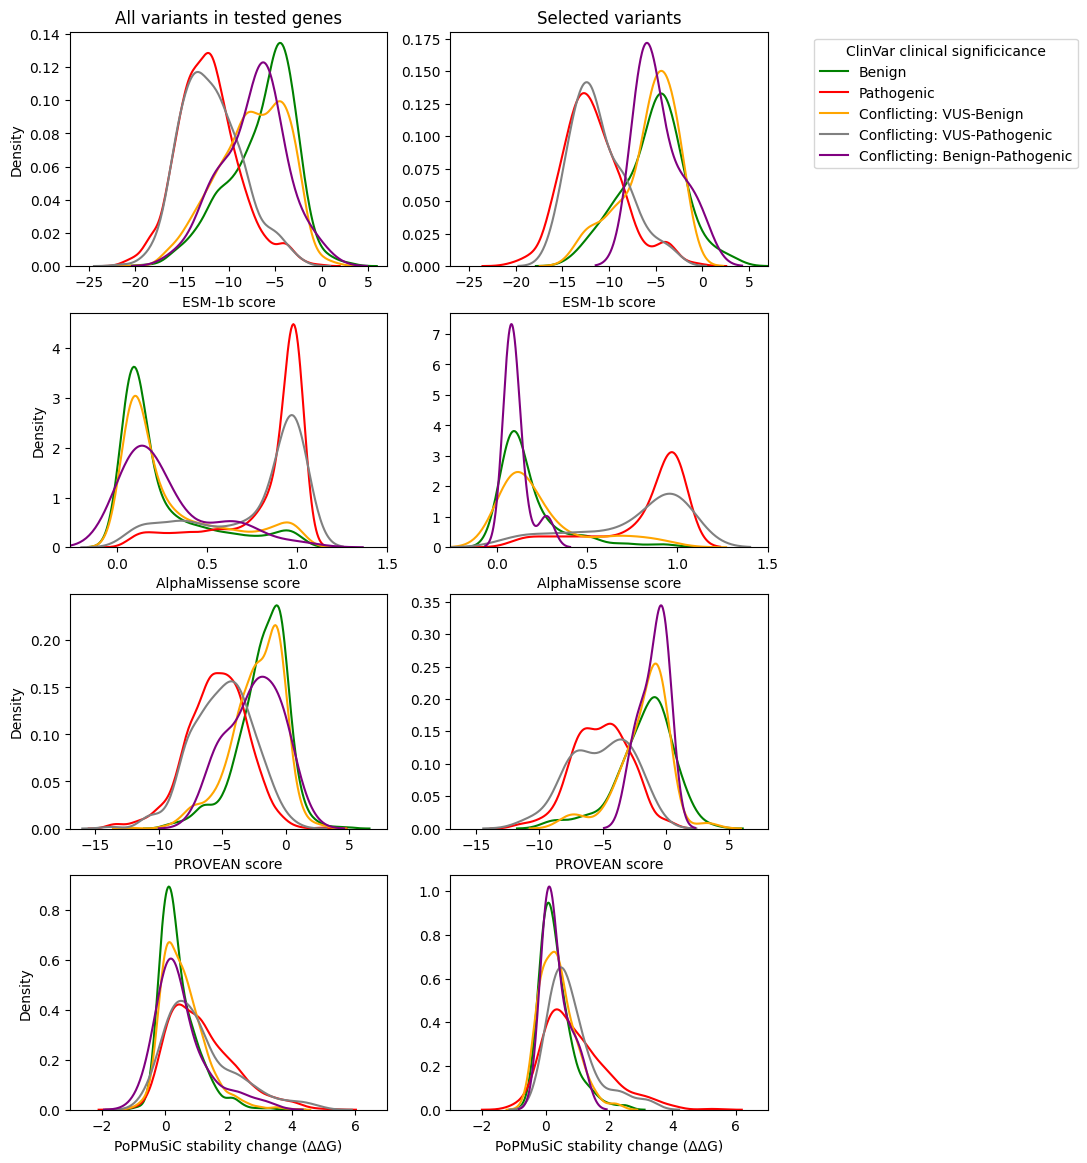

In [ ]:
range_d = {'esm1b':(-27,7),
           'alpha_missense':(-.26,1.5),
           'provean':(-17,8),
           'pop_music':(-3,7),
           'solvant_acc':(0,100),
           'af_plddt':(0,100),
           }

fig, axs = plt.subplots(nrows=4, ncols=2, figsize=(9,14))

for row, assay in zip(axs, ['esm1b','alpha_missense','provean','pop_music']):

    for cs,color in zip(['Benign','Pathogenic'],['green','red']):
        df = clinvar_onepercent[clinvar_onepercent.clinical_significance_simple == cs]
        dfo = clinvar_onepercent[(clinvar_onepercent.clinical_significance_simple == cs)&(clinvar_onepercent.one_percent)]
        sns.kdeplot(data=df, x=df[assay], color=color, ax=row[0], label=cs)
        sns.kdeplot(data=dfo, x=dfo[assay], color=color, ax=row[1], label=cs)
    
    for conflicting_class,color in zip(['Conflicting: Benign-VUS','Conflicting: Pathogenic-VUS','Conflicting: Benign-Pathogenic'],['orange','gray','purple']):
        df = clinvar_onepercent[(clinvar_onepercent.conflicting_class == conflicting_class)&(clinvar_onepercent.clinical_significance_simple == 'Conflicting')]
        dfo = clinvar_onepercent[(clinvar_onepercent.conflicting_class == conflicting_class)&(clinvar_onepercent.clinical_significance_simple == 'Conflicting')&(clinvar_onepercent.one_percent)]
        sns.kdeplot(data=df, x=df[assay], color=color, ax=row[0], label=conflicting_class)
        sns.kdeplot(data=dfo, x=dfo[assay], color=color, ax=row[1], label=conflicting_class)
    
    
    row[0].set_xlim(range_d[assay])
    row[1].set_xlim(range_d[assay])

    if assay == 'esm1b':
        row[1].legend(loc='upper right', bbox_to_anchor=(2, 1), title='ClinVar clinical significicance')
        row[0].set_title('All variants in tested genes')
        row[1].set_title('Selected variants')

    axs[0][1].set_ylabel('')
    axs[1][1].set_ylabel('')
    axs[2][1].set_ylabel('')
    axs[3][1].set_ylabel('')

    axs[0][0].set_xlabel('ESM-1b score')
    axs[0][1].set_xlabel('ESM-1b score')
    axs[1][0].set_xlabel('AlphaMissense score')
    axs[1][1].set_xlabel('AlphaMissense score')
    axs[2][0].set_xlabel('PROVEAN score')
    axs[2][1].set_xlabel('PROVEAN score')
    axs[3][0].set_xlabel('PoPMuSiC stability change (ΔΔG)')
    axs[3][1].set_xlabel('PoPMuSiC stability change (ΔΔG)')

# Edit legend labels using dictionary
legend_label_dict = {
    'Conflicting: Benign-VUS':'Conflicting: VUS-Benign',
    'Conflicting: Pathogenic-VUS':'Conflicting: VUS-Pathogenic',
}
handles, labels = row[1].get_legend_handles_labels()
new_labels = [legend_label_dict.get(label, label) for label in labels]
axs[0][1].legend(handles, new_labels, loc='upper right', bbox_to_anchor=(2, 1), title='ClinVar clinical significicance')

plt.show()